# 01 — Baseline

Treina a CNN de referência. Todas as ablações do notebook 02 partem exatamente desta configuração e mudam um único argumento.

In [1]:
# Setup: no Colab (site ou extensão do VS Code) clona o repositório do GitHub
# e instala as dependências; localmente só ajusta o sys.path.
# USE_DRIVE guarda pesos, JSONs e figuras no Google Drive para sobreviverem ao
# fim da sessão (o notebook 04 precisa dos pesos).
import os, shutil, sys
USE_DRIVE = True
# Detecta o Colab pela pasta /content em vez de "google.colab": no kernel da
# extensão do VS Code esse módulo pode não estar carregado.
IN_COLAB = os.path.isdir("/content") or "google.colab" in sys.modules
if IN_COLAB:
    REPO = "/content/deep-vision-classification"
    # O código que roda é o do GitHub, não o da sua máquina: faça push antes.
    if not os.path.exists(REPO):
        !git clone -q https://github.com/davimoljo/deep-vision-classification.git {REPO}
    else:
        !git -C {REPO} pull -q
    %cd {REPO}
    !pip install -q -r requirements.txt
    import torch
    # Sem GPU o treino cai para a CPU sem avisar: a baseline levou ~3 h em vez
    # de ~15 min. Melhor parar aqui do que descobrir no fim do treino.
    if not torch.cuda.is_available():
        raise RuntimeError("Servidor sem GPU. Remova este servidor e crie outro "
                           "do Colab com GPU (T4), depois rode esta célula de novo.")
    print("GPU:", torch.cuda.get_device_name(0))
    if USE_DRIVE:
        if not os.path.isdir("/content/drive/MyDrive"):
            try:
                from google.colab import drive
                drive.mount("/content/drive")
            except Exception as e:
                print("Não montou o Drive:", e)
                print("No VS Code use 'Colab: Mount Google Drive to Server...' e rode esta célula de novo.")
        if os.path.isdir("/content/drive/MyDrive"):
            os.environ["OUTPUT_ROOT"] = "/content/drive/MyDrive/deep-vision-classification"
            print("Saídas em", os.environ["OUTPUT_ROOT"])
            # Baixar o CIFAR-10 do site original leva ~15 min a cada servidor
            # novo; com uma cópia do arquivo no Drive, as próximas vezes levam
            # segundos. O torchvision reaproveita o .tar.gz se o MD5 bater.
            cache = os.path.join(os.environ["OUTPUT_ROOT"], "data", "cifar-10-python.tar.gz")
            local = os.path.join(REPO, "data", "cifar-10-python.tar.gz")
            os.makedirs(os.path.dirname(local), exist_ok=True)
            if os.path.exists(cache) and not os.path.exists(local):
                shutil.copy(cache, local)
            from torchvision import datasets
            datasets.CIFAR10(os.path.join(REPO, "data"), train=True, download=True)
            if not os.path.exists(cache) and os.path.exists(local):
                os.makedirs(os.path.dirname(cache), exist_ok=True)
                shutil.copy(local, cache)
        else:
            print("ATENÇÃO: sem Drive, resultados e pesos somem quando o servidor desligar.")
    ROOT = REPO
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

Mounted at /content/drive
Saídas em /content/drive/MyDrive/deep-vision-classification


In [2]:
from src.pipeline import (DEFAULTS, STRATEGIES, build_cnn, build_from_config,
                          build_pretrained, count_parameters, evaluate_on_test, fit,
                          get_loaders, list_results, load_best_weights, load_result,
                          result_exists)
from src.plots import comparison_table, per_class_accuracy, plot_confusion, plot_curves
DEFAULTS

{'epochs': 30,
 'batch_size': 128,
 'lr': 0.001,
 'weight_decay': 0.0005,
 'optimizer': 'adamw',
 'scheduler': 'cosine'}

## Configuração

`BASELINE = {}` significa os valores padrão de `BaselineCNN` (3 blocos, 32 filtros, kernel 3, 2 convs/bloco, BN, dropout 0.3, FC 256, flatten).

In [3]:
RUN = "baseline"
BASELINE = {}
loaders = get_loaders(DEFAULTS["batch_size"], img_size=32, augment=True)
model = build_cnn(**BASELINE)
total, trainable = count_parameters(model)
print(model)
print(f"{total:,} parâmetros ({trainable:,} treináveis)")

100%|██████████| 170M/170M [16:15<00:00, 175kB/s] 


BaselineCNN(
  (features): Sequential(
    (0): ConvBlock(
      (body): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): ConvBlock(
      (body): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=Fa

## Treino

In [4]:
result = fit(model, loaders, RUN)

[baseline] ep   1/30 | train 1.4993/0.4471 | val 1.1683/0.5746  *
[baseline] ep   2/30 | train 1.0562/0.6246 | val 0.9953/0.6466  *
[baseline] ep   3/30 | train 0.8909/0.6878 | val 0.8248/0.7090  *
[baseline] ep   4/30 | train 0.8017/0.7227 | val 0.7407/0.7404  *
[baseline] ep   5/30 | train 0.7338/0.7464 | val 0.7567/0.7400
[baseline] ep   6/30 | train 0.6791/0.7656 | val 0.6637/0.7742  *
[baseline] ep   7/30 | train 0.6439/0.7769 | val 0.5891/0.8032  *
[baseline] ep   8/30 | train 0.6015/0.7929 | val 0.5268/0.8186  *
[baseline] ep   9/30 | train 0.5740/0.8039 | val 0.5211/0.8222  *
[baseline] ep  10/30 | train 0.5390/0.8173 | val 0.5356/0.8172
[baseline] ep  11/30 | train 0.5223/0.8229 | val 0.5167/0.8214
[baseline] ep  12/30 | train 0.4980/0.8301 | val 0.5170/0.8298  *
[baseline] ep  13/30 | train 0.4743/0.8376 | val 0.4740/0.8376  *
[baseline] ep  14/30 | train 0.4500/0.8463 | val 0.4365/0.8516  *
[baseline] ep  15/30 | train 0.4342/0.8526 | val 0.4277/0.8542  *
[baseline] ep  16/3

## Curvas (diagnóstico de overfitting)

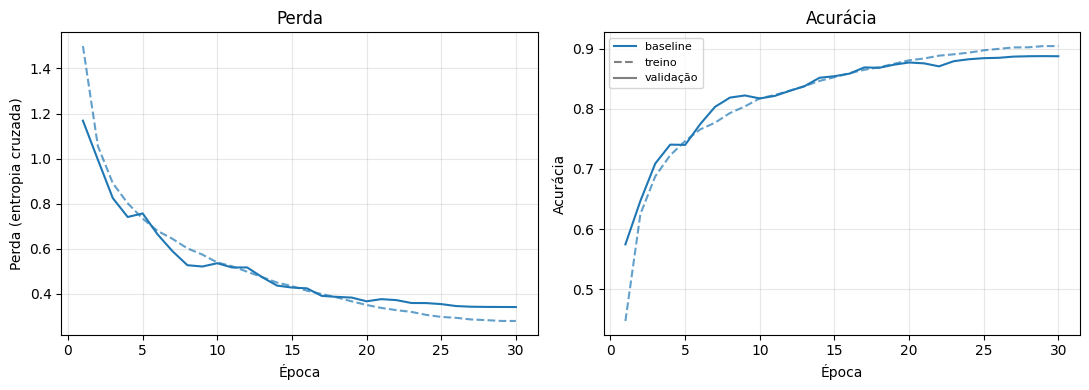

In [5]:
plot_curves(RUN);